# CellVOCAL analysis of the developing mouse cortex

This tutorial follows the cortical analysis described in the Methods. A prepared Slide-seq H5AD is modeled with a weak spatial prior oriented from ventricular to cortical plate regions, while CellVOCAL jointly estimates RNA velocity and communication influence.

> Start Jupyter from the repository root. Training is commented by default.

## Model specification

The negative x-coordinate orients the temporal prior. A 45-neighbor graph captures local tissue structure, and a single candidate event per receiver-module group keeps influence focused on the strongest plausible sender.

In [1]:
from base64 import b64encode
from pathlib import Path
import sys

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "model").is_dir():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import anndata as ad
import numpy as np
import pandas as pd
import torch
from IPython.display import HTML, display
from IPython.utils.capture import capture_output

from model.train.config import CellVOCALConfig
from pipeline.analysis import CellVOCALAnalysis
from pipeline.cellvocal import run_cellvocal
from utils.tools.real_time_prior import set_real_time_prior


In [2]:
DATA_ROOT = ROOT / "paper" / "data" / "mouse_brain_cortex"

cfg = CellVOCALConfig()
cfg.train.device = "cuda:0" if torch.cuda.is_available() else "cpu"
cfg.train.checkpoint_dir = DATA_ROOT / "cellvocal" / "checkpoints"
cfg.eval.output_dir = DATA_ROOT / "cellvocal" / "results"
cfg.model.use_cell_annotation = False
cfg.model.ccc_velocity_scale = 0.3
cfg.graph.n_spatial_neighbors = 45
cfg.graph.ccc_event_budget_per_receiver = 1
cfg.train.time_prior_source = "spatial"
cfg.train.time_prior_spatial_signs = (-1.0,)
cfg.train.velocity_order_min_delta = 1e-4
cfg.train.lr = 3e-4
cfg.train.w_time = 0.8

## Train CellVOCAL

The prepared H5AD is read directly. The only schema alignment copies its existing `X_spatial` coordinates to the standard `spatial` key expected by the model.

In [3]:
# adata = ad.read_h5ad(DATA_ROOT / "raw" / "slide-seq-adult-cortex_pp.h5ad")
# adata.obsm["spatial"] = np.asarray(adata.obsm["X_spatial"], dtype=float)
# result = run_cellvocal(adata, config=cfg)

## Evaluate the cortical developmental axis

The central result is a monotonic inferred-time shift across cortical layers. Spot counts and within-layer IQR expose imbalanced or uncertain regions; the direction metrics and three spatial maps provide complementary global checks.

,spots,spots (%),median_time,time IQR
clusters,,,,
VZ,324,12.898,0.207,0.056
SVZ,957,38.097,0.349,0.159
IZ,58,2.309,0.499,0.146
CP,516,20.541,0.659,0.150
L5/6,603,24.005,0.754,0.181
CR Cells,54,2.150,0.842,0.043


,Dataset,Brain cortex
Metrics,Model,
Time Correlation,CellVOCAL,0.996
Spatial Velocity Consistency,CellVOCAL,0.955
Spatial Time Consistency,CellVOCAL,0.994
CBDir,CellVOCAL,0.287



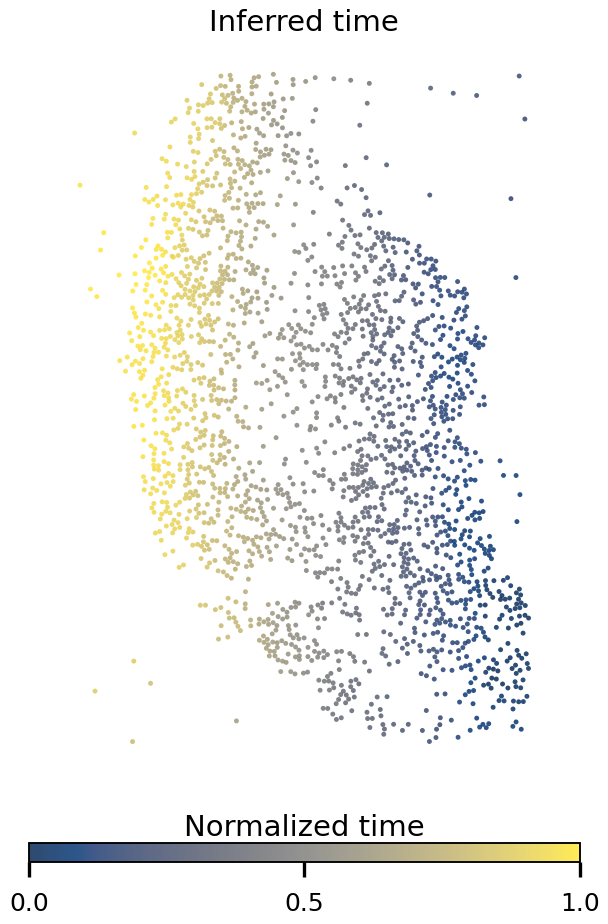
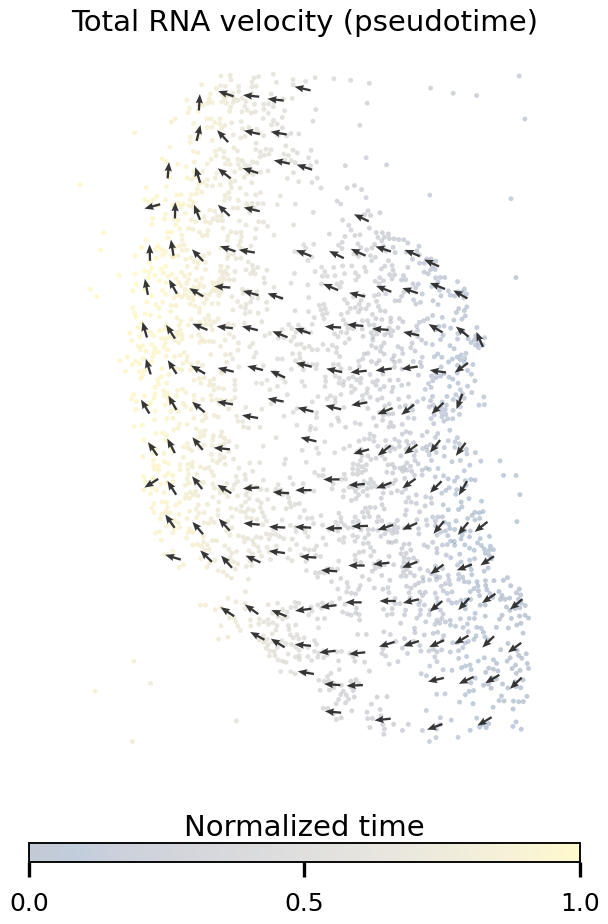
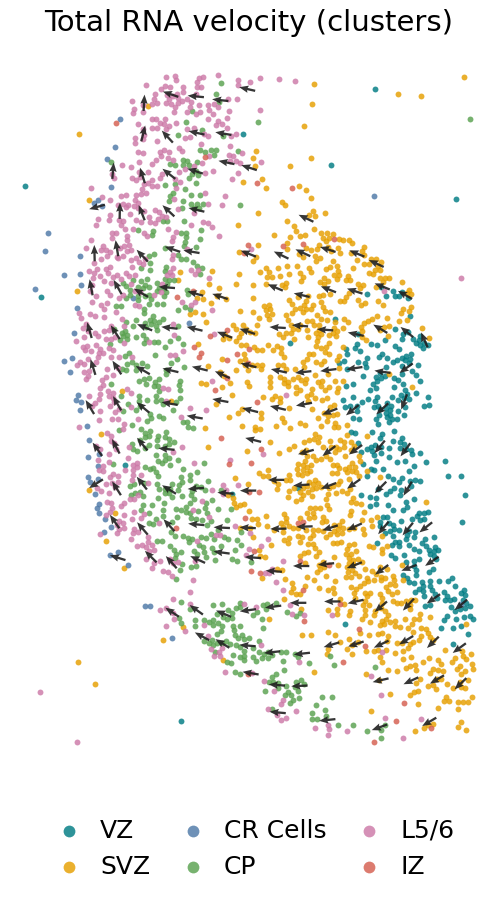

In [4]:
analysis = CellVOCALAnalysis.from_h5ad(cfg.eval.output_dir / "out.h5ad", config=cfg)
cortical_order = ["VZ", "SVZ", "IZ", "CP", "L5/6", "CR Cells"]
stage_summary = analysis.adata.obs.groupby("clusters", observed=True)["cv_time"].agg(
    spots="size", median_time="median", q25=lambda x: x.quantile(0.25), q75=lambda x: x.quantile(0.75)
).reindex(cortical_order)
stage_summary["spots (%)"] = 100 * stage_summary["spots"] / stage_summary["spots"].sum()
stage_summary["time IQR"] = stage_summary["q75"] - stage_summary["q25"]
display(stage_summary[["spots", "spots (%)", "median_time", "time IQR"]].round(3))

with capture_output():
    set_real_time_prior(analysis.adata, "mouse_brain_cortex")
    metrics = analysis.evaluate_metrics(cluster_edges=[("VZ", "SVZ"), ("SVZ", "IZ"), ("IZ", "CP"), ("CP", "L5/6")], dataset_name="Brain cortex", n_jobs=cfg.eval.benchmark_n_jobs)
display(metrics)
with capture_output():
    velocity_plots = analysis.plot_velocity(output_dir=DATA_ROOT / "cellvocal" / "velocity")
image_tiles = []
for path in velocity_plots:
    encoded = b64encode(Path(path).read_bytes()).decode("ascii")
    image_tiles.append(f'<img src="data:image/png;base64,{encoded}" alt="{Path(path).stem}" style="flex:1 1 0;min-width:0;width:32%;height:auto;object-fit:contain">')
display(HTML('<div style="display:flex;flex-wrap:nowrap;gap:8px;align-items:flex-start;width:100%">' + "".join(image_tiles) + "</div>"))

Interpret a coherent fit as agreement between the ordered-region metrics, the spatial latent-time gradient, and the direction of the velocity arrows.